#### MPAS Mesh Quality Diagnostics
- Cell-size (effective diameter) distribution
- Edge-length distribution
- Per-cell shape metric (edge-length coefficient of variation) as a map

A quick QC pass to run on any new variable-resolution mesh before trusting simulations on it -- flags refinement-zone irregularities or mesh-generation defects that are easy to miss in a plain mesh-edge plot.

**Data**: SouthAmerica 240-48km variable-resolution tutorial mesh (`SouthAmerica.init.nc`).

Ming Ge Nov. 2026

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from mpas_utils import mpas_lonlat_deg, cell_edge_length_cv

#### Load mesh geometry

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'
ds = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')

areaCell = ds['areaCell'].values                 # m^2
dvEdge = ds['dvEdge'].values                      # m, edge length
nEdgesOnCell = ds['nEdgesOnCell'].values
edgesOnCell = ds['edgesOnCell'].values            # 1-based, 0-padded

lonCell, latCell = mpas_lonlat_deg(ds['lonCell'].values, ds['latCell'].values)
triang = tri.Triangulation(lonCell, latCell)

#### Cell-size distribution (effective diameter = diameter of a circle with the same area)

diameter range: 42.8 - 276.4 km


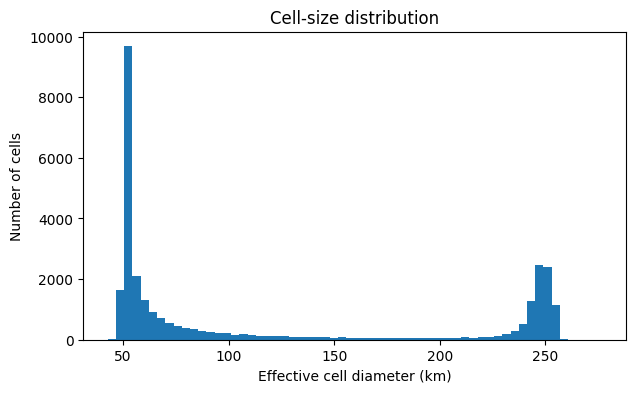

In [3]:
diam_km = np.sqrt(4 * areaCell / np.pi) / 1000.0

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(diam_km, bins=60, color='tab:blue')
ax.set_xlabel('Effective cell diameter (km)')
ax.set_ylabel('Number of cells')
ax.set_title('Cell-size distribution')
print(f'diameter range: {diam_km.min():.1f} - {diam_km.max():.1f} km')

#### Edge-length distribution

edge length range: 10.6 - 199.0 km


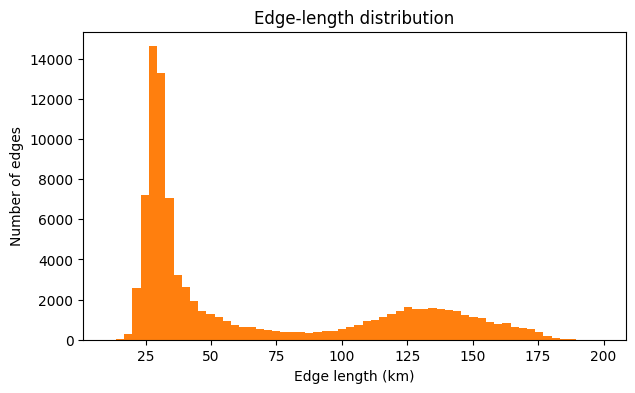

In [4]:
dv_km = dvEdge / 1000.0

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(dv_km, bins=60, color='tab:orange')
ax.set_xlabel('Edge length (km)')
ax.set_ylabel('Number of edges')
ax.set_title('Edge-length distribution')
print(f'edge length range: {dv_km.min():.1f} - {dv_km.max():.1f} km')

#### Per-cell shape metric
Coefficient of variation (std/mean) of the edge lengths around each cell -- near 0 for a regular hexagon, larger where refinement transitions, pentagons/heptagons, or mesh defects distort cell shape.

`cell_edge_length_cv` is a plain Python loop over cells (fine at this mesh's 30k cells, ~0.3s). On a production global mesh with tens of millions of cells it would take minutes -- vectorize with `np.add.reduceat`-style indexing over `edgesOnCell` if that becomes a bottleneck.

3087 / 30210 cells (10.22%) have CV > 0.2


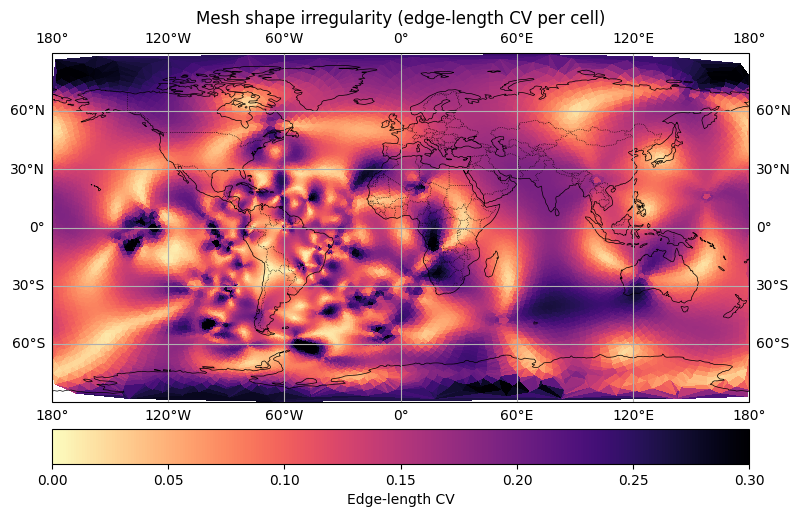

In [5]:
cv = cell_edge_length_cv(nEdgesOnCell, edgesOnCell, dvEdge)

fig, ax = plt.subplots(figsize=(9, 7), subplot_kw={'projection': ccrs.PlateCarree()})
mm = ax.tripcolor(triang, cv, cmap='magma_r', vmin=0, vmax=0.3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(draw_labels=True)
plt.colorbar(mm, orientation='horizontal', pad=0.05, label='Edge-length CV')
ax.set_title('Mesh shape irregularity (edge-length CV per cell)')

flagged = (cv > 0.2).sum()
print(f'{flagged} / {cv.size} cells ({100*flagged/cv.size:.2f}%) have CV > 0.2')